# 04. Midterm results

Baseline table, per-class F1 and confusion matrices, leakage sensitivity and the Midterm questions E1-E4. Reads only the saved predictions and logs in `results/` (no model is re-run) and runs on CPU. Answers: [`docs/midterm_answers.md`](../docs/midterm_answers.md).

*Generated by `scripts/build_notebooks.py` from the `.py` files; edit those and rebuild, not this notebook.*

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/DataSEC-Sound-Classification")  # <- where the repository is on Drive
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
# os.environ["ATI_CONFIG"] = "configs/default.yaml"  # optional: another config (read when src.utils is imported)

import pandas as pd
from IPython.display import Image, display

print("repository:", ROOT)

repository: C:\ATI\DataSEC-Sound-Classification-main


## 1. Baseline table (part D)

Source: `scripts/make_baseline_table.py`

Build the Midterm baseline table (T2.3) from training logs + clean prediction CSVs.

Accuracy / macro-F1 are recomputed from results/predictions/*_none_0.csv and checked against the
JSON log. Runs whose split_md5 differs from the committed splits/ are refused.

In [2]:
import hashlib
import json
import sys
from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from src.utils import RESULTS, load_config, resolve

In [3]:
MODELS = ["small_cnn", "mobilenetv3s", "crnn"]  # table row order

In [4]:
def split_ids(splits_dir: Path, split: str) -> set[str]:
    return set(pd.read_csv(splits_dir / f"{split}.csv").sample_id)

In [5]:
def scores_from_csv(path: Path, classes: list[str], expected_ids: set[str]) -> tuple[float, float]:
    df = pd.read_csv(path)
    assert set(df.sample_id) == expected_ids and len(df) == len(expected_ids), f"{path.name}: ids != split"
    acc = accuracy_score(df.true_class, df.pred_class)
    f1 = f1_score(df.true_class, df.pred_class, labels=classes, average="macro", zero_division=0)
    return float(acc), float(f1)

In [6]:
def main_make_baseline_table() -> None:
    cfg = load_config()
    results = RESULTS
    splits_dir = resolve(cfg["dataset"]["splits_dir"])
    classes = json.loads(resolve("configs/classes.json").read_text(encoding="utf-8"))
    canonical = {s: hashlib.md5((splits_dir / f"{s}.csv").read_bytes()).hexdigest() for s in ["train", "val", "test"]}
    ids = {s: split_ids(splits_dir, s) for s in ["val", "test"]}

    rows = []
    for log_path in sorted((results / "logs").glob("*_seed*.json")):
        L = json.loads(log_path.read_text(encoding="utf-8"))
        if L.get("split_md5") != canonical:
            print(f"SKIP {log_path.name}: trained on a non-canonical split")
            continue
        row = {"model": L["model"], "seed": L["seed"]}
        for split in ["val", "test"]:
            csv = results / "predictions" / f"{L['model']}_seed{L['seed']}_{split}_none_0.csv"
            acc, f1 = scores_from_csv(csv, classes, ids[split])
            assert abs(acc - L[split]["accuracy"]) < 1e-6 and abs(f1 - L[split]["macro_f1"]) < 1e-6, \
                f"{csv.name}: CSV scores differ from {log_path.name}"
            row[f"{split}_acc"], row[f"{split}_macro_f1"] = acc, f1
        row.update({
            "params_M": L["params"] / 1e6,
            "MACs_M": L["macs"] / 1e6,
            "latency_ms": L["latency_ms"],
            "train_time_min": L["train_time_s"] / 60,
            "best_epoch": L["best_epoch"],
            "epochs_run": len(L["history"]),
            "gpu": L["env"].get("gpu"),
        })
        rows.append(row)

    assert rows, "no valid runs in results/logs"
    df = pd.DataFrame(rows)
    df["model"] = pd.Categorical(df["model"], [m for m in MODELS if m in set(df.model)] +
                                 sorted(set(df.model) - set(MODELS)), ordered=True)
    df = df.sort_values(["model", "seed"]).reset_index(drop=True)
    out = results / "tables" / "midterm_baselines.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    df.round(4).to_csv(out, index=False)
    print(df.round(4).to_string(index=False))
    print(f"-> {out}")

In [7]:
# same as: python scripts/make_baseline_table.py
sys.argv = ["scripts/make_baseline_table.py"]
main_make_baseline_table()

       model  seed  val_acc  val_macro_f1  test_acc  test_macro_f1  params_M   MACs_M  latency_ms  train_time_min  best_epoch  epochs_run                           gpu
   small_cnn    42   0.9327        0.8605    0.9340         0.8783    0.3940 198.4077      1.1691          3.1829          50          50 NVIDIA GeForce RTX 2060 SUPER
   small_cnn    43   0.9142        0.8404    0.9182         0.8599    0.3940 198.4077      1.1902          2.7524          28          36 NVIDIA GeForce RTX 2060 SUPER
   small_cnn    44   0.9274        0.8565    0.9406         0.8903    0.3940 198.4077      1.1898          3.2349          50          50 NVIDIA GeForce RTX 2060 SUPER
mobilenetv3s    42   0.9301        0.8719    0.9301         0.8700    1.5404  18.1147      6.0248          2.4526          17          25 NVIDIA GeForce RTX 2060 SUPER
mobilenetv3s    43   0.9393        0.8805    0.9578         0.9204    1.5404  18.1147      8.6253          4.2175          37          45 NVIDIA GeForce RTX 206

In [8]:
from src.utils import RESULTS

display(pd.read_csv(RESULTS / "tables" / "midterm_baselines.csv"))

,model,seed,val_acc,val_macro_f1,test_acc,test_macro_f1,params_M,MACs_M,latency_ms,train_time_min,best_epoch,epochs_run,gpu
0,small_cnn,42,0.9327,0.8605,0.9340,0.8783,0.3940,198.4077,1.1691,3.1829,50,50,NVIDIA GeForce RTX 2060 SUPER
1,small_cnn,43,0.9142,0.8404,0.9182,0.8599,0.3940,198.4077,1.1902,2.7524,28,36,NVIDIA GeForce RTX 2060 SUPER
2,small_cnn,44,0.9274,0.8565,0.9406,0.8903,0.3940,198.4077,1.1898,3.2349,50,50,NVIDIA GeForce RTX 2060 SUPER
3,mobilenetv3s,42,0.9301,0.8719,0.9301,0.8700,1.5404,18.1147,6.0248,2.4526,17,25,NVIDIA GeForce RTX 2060 SUPER
4,mobilenetv3s,43,0.9393,0.8805,0.9578,0.9204,1.5404,18.1147,8.6253,4.2175,37,45,NVIDIA GeForce RTX 2060 SUPER
5,mobilenetv3s,44,0.9380,0.8813,0.9578,0.9138,1.5404,18.1147,5.9850,4.4859,42,50,NVIDIA GeForce RTX 2060 SUPER
6,crnn,42,0.9327,0.8688,0.9301,0.8720,0.8688,486.5690,1.4667,2.7879,34,42,NVIDIA GeForce RTX 2060 SUPER
7,crnn,43,0.9406,0.8879,0.9274,0.8664,0.8688,486.5690,1.4752,3.0010,32,40,NVIDIA GeForce RTX 2060 SUPER
8,crnn,44,0.9420,0.8902,0.9367,0.8868,0.8688,486.5690,1.4745,3.2190,46,50,NVIDIA GeForce RTX 2060 SUPER


## 2. Per-class F1 and confusion matrices (part D)

Source: `scripts/plot_metrics.py`

Midterm part D figures: per-class F1 and row-normalized confusion matrices on the clean test set.

Everything is recomputed from the saved prediction CSVs (results/predictions/*_none_0.csv) and checked
against the JSON training logs; no model is re-run.

In [9]:
import argparse
import json
import sys
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix, f1_score
from src.utils import RESULTS, load_classes

In [10]:
MODELS = ["small_cnn", "mobilenetv3s", "crnn"]
COLORS = {"small_cnn": "#2a78d6", "mobilenetv3s": "#eb6834", "crnn": "#1baf7a"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
SHORT = {"Cat fights and moans": "Cat", "Cicadas and crickets": "Cicadas/crickets",
         "Crows seagulls and magpies": "Crows/gulls", "Dog barkings and howlings": "Dog",
         "Lawn mower brush cutter and olive shaker": "Lawn mower/cutter", "Sirens and alarms": "Sirens/alarms",
         "Thunder fireworks and gunshot": "Thunder/gunshot", "Vacuum cleaner fan and hairdryer": "Vacuum/fan/dryer"}

In [11]:
def main_plot_metrics() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()
    classes = load_classes()
    fig_dir, tab_dir = RESULTS / "figures", RESULTS / "tables"
    fig_dir.mkdir(parents=True, exist_ok=True); tab_dir.mkdir(parents=True, exist_ok=True)

    pred, logs = {}, {}
    for m in MODELS:
        pred[m] = pd.read_csv(RESULTS / "predictions" / f"{m}_seed{args.seed}_test_none_0.csv")
        logs[m] = json.loads((RESULTS / "logs" / f"{m}_seed{args.seed}.json").read_text(encoding="utf-8"))
        f1 = f1_score(pred[m].true_class, pred[m].pred_class, labels=classes, average="macro", zero_division=0)
        assert abs(f1 - logs[m]["test"]["macro_f1"]) < 1e-9, f"{m}: CSV and log disagree"

    # per-class F1, hardest classes on top (sorted by the mean over the three models)
    f1c = pd.DataFrame({m: f1_score(pred[m].true_class, pred[m].pred_class, labels=classes, average=None,
                                    zero_division=0) for m in MODELS}, index=classes)
    f1c["mean"] = f1c[MODELS].mean(axis=1)
    f1c["n_test"] = pred[MODELS[0]].true_class.value_counts().reindex(classes).fillna(0).astype(int).values
    f1c = f1c.sort_values("mean")
    f1c.iloc[::-1].round(4).to_csv(tab_dir / "test_per_class_f1.csv", index_label="class")

    fig, ax = plt.subplots(figsize=(10, 11))
    y, h = np.arange(len(f1c)), 0.26
    for k, m in enumerate(MODELS):
        ax.barh(y + (k - 1) * h, f1c[m], height=h * 0.9, color=COLORS[m], label=m)
    ax.set_yticks(y, [f"{c}  (n={n})" for c, n in zip(f1c.index, f1c.n_test)], fontsize=9)
    ax.set_xlim(0, 1.0); ax.set_xlabel("test F1"); ax.grid(axis="y", visible=False)
    ax.set_title(f"Per-class test F1, seed {args.seed} (hardest classes on top)")
    ax.legend(loc="lower right", frameon=True)
    plt.tight_layout(); plt.savefig(fig_dir / "test_per_class_f1.png", dpi=150); plt.close()

    # confusion matrices, row-normalized (diagonal = per-class recall); counts are in the JSON logs
    short = [SHORT.get(c, c) for c in classes]
    for m in MODELS:
        cm = confusion_matrix(pred[m].true_class, pred[m].pred_class, labels=classes)
        assert (cm == np.array(logs[m]["test"]["confusion_matrix"])).all(), f"{m}: confusion matrix != log"
        cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(11, 9.5))
        im = ax.imshow(cmn, cmap=BLUES, vmin=0, vmax=1)
        for i, j in zip(*np.where(cmn >= 0.10)):
            ax.text(j, i, f"{cmn[i, j]:.2f}".lstrip("0"), ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.6 else "#1a1a19")
        ax.set_xticks(range(len(classes)), short, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(len(classes)), short, fontsize=8)
        ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.grid(False)
        ax.set_title(f"{m}: test confusion matrix, row-normalized (macro-F1 {logs[m]['test']['macro_f1']:.3f})")
        fig.colorbar(im, ax=ax, fraction=0.04, label="fraction of true class")
        plt.tight_layout(); plt.savefig(fig_dir / f"confusion_{m}.png", dpi=150); plt.close()

    print(f1c.iloc[::-1].round(2).to_string())
    print(f"-> {fig_dir}/test_per_class_f1.png, confusion_*.png | {tab_dir}/test_per_class_f1.csv")

In [12]:
# same as: python scripts/plot_metrics.py --seed 42
sys.argv = ["scripts/plot_metrics.py", "--seed", "42"]
main_plot_metrics()

                                          small_cnn  mobilenetv3s  crnn  mean  n_test
Voices                                         1.00          0.99  0.99  0.99     285
Cicadas and crickets                           1.00          0.95  1.00  0.98      11
Chicken coop                                   0.95          1.00  1.00  0.98       9
Music                                          0.99          0.97  0.98  0.98     150
Thunder fireworks and gunshot                  0.97          0.96  0.99  0.97      35
Wind turbine                                   1.00          0.97  0.94  0.97      15
Cat fights and moans                           0.94          0.93  1.00  0.96       8
Sirens and alarms                              0.94          0.94  0.97  0.95      17
Glass breaking                                 0.94          0.97  0.94  0.95      17
Birds                                          1.00          0.84  1.00  0.95       9
Dog barkings and howlings                      1.00   

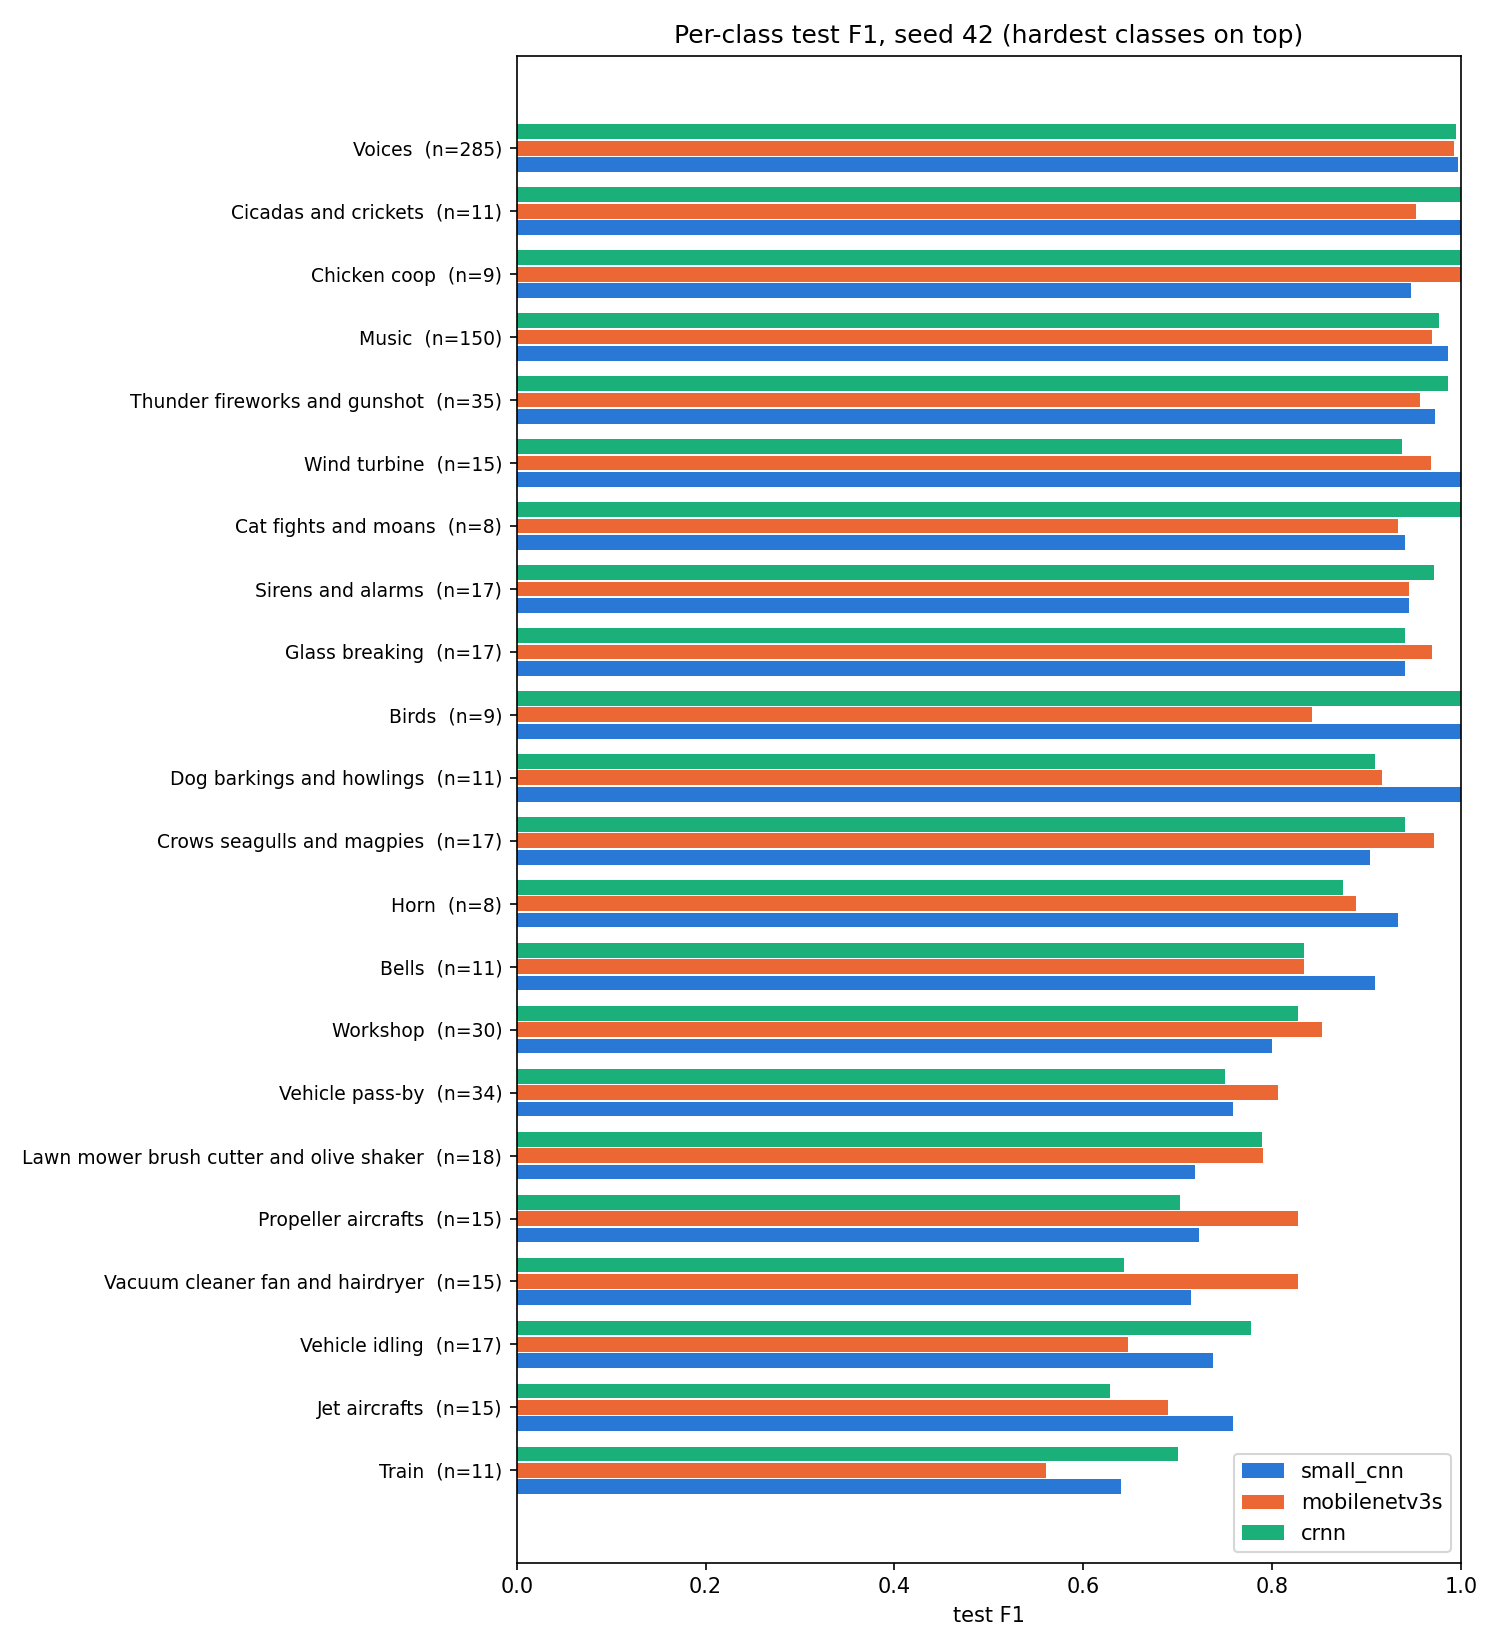

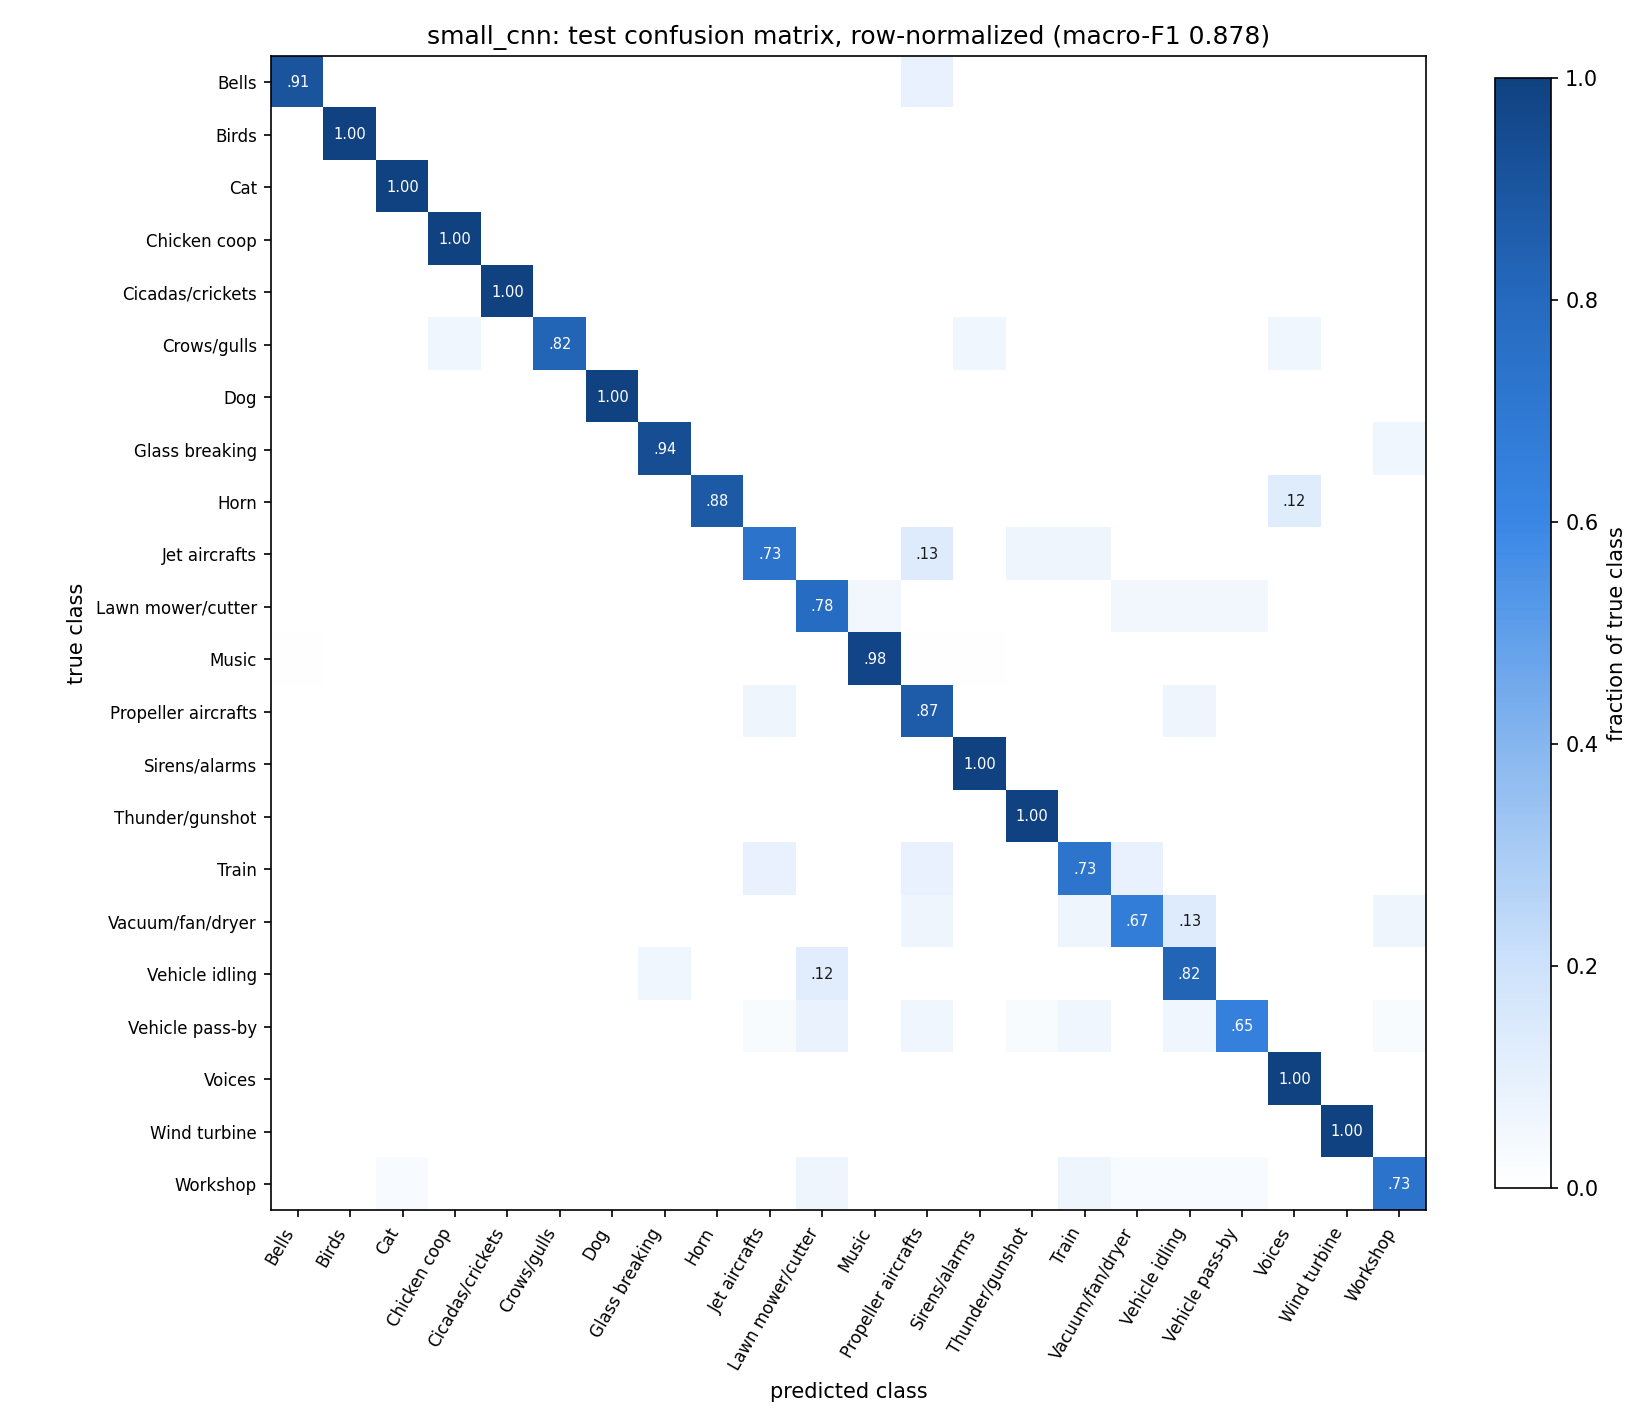

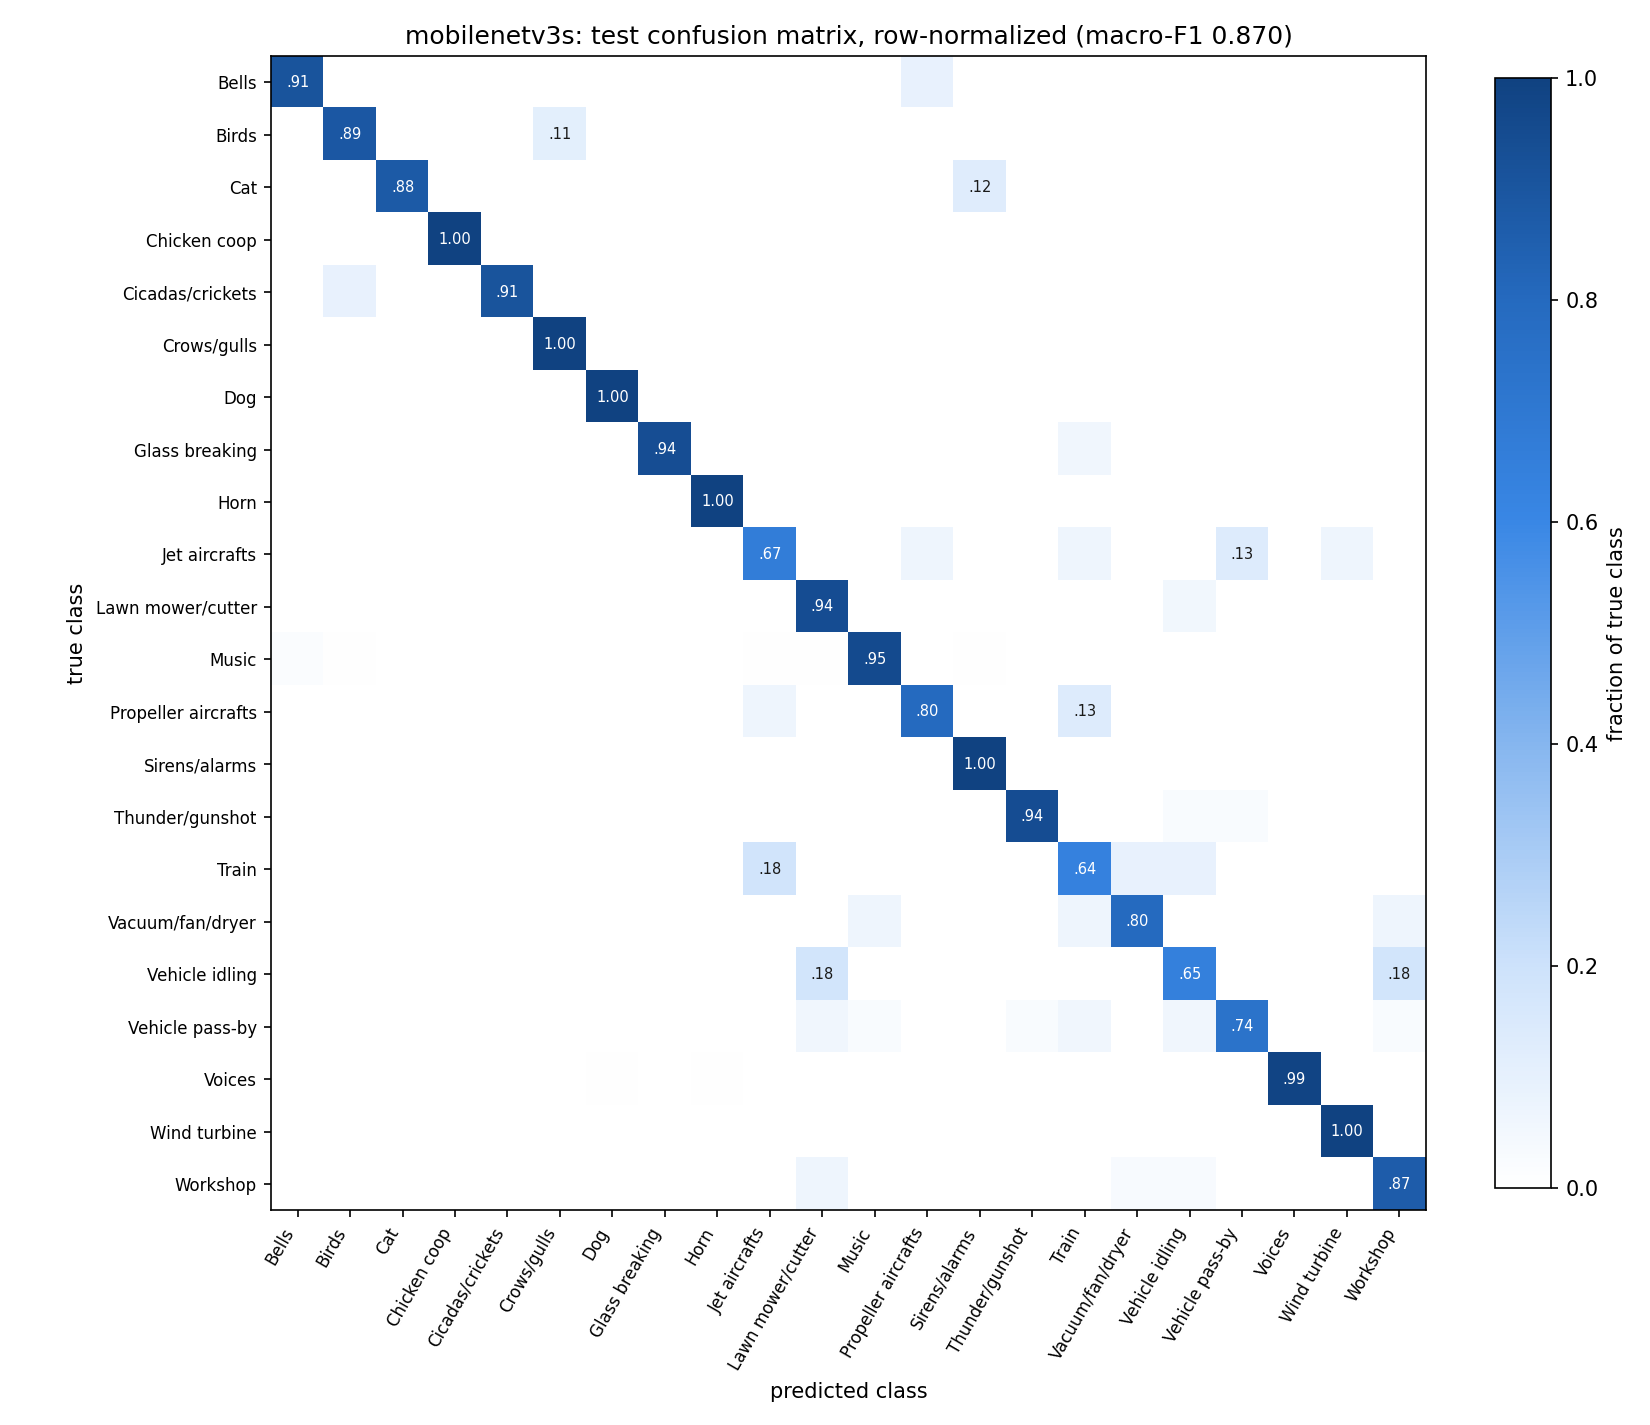

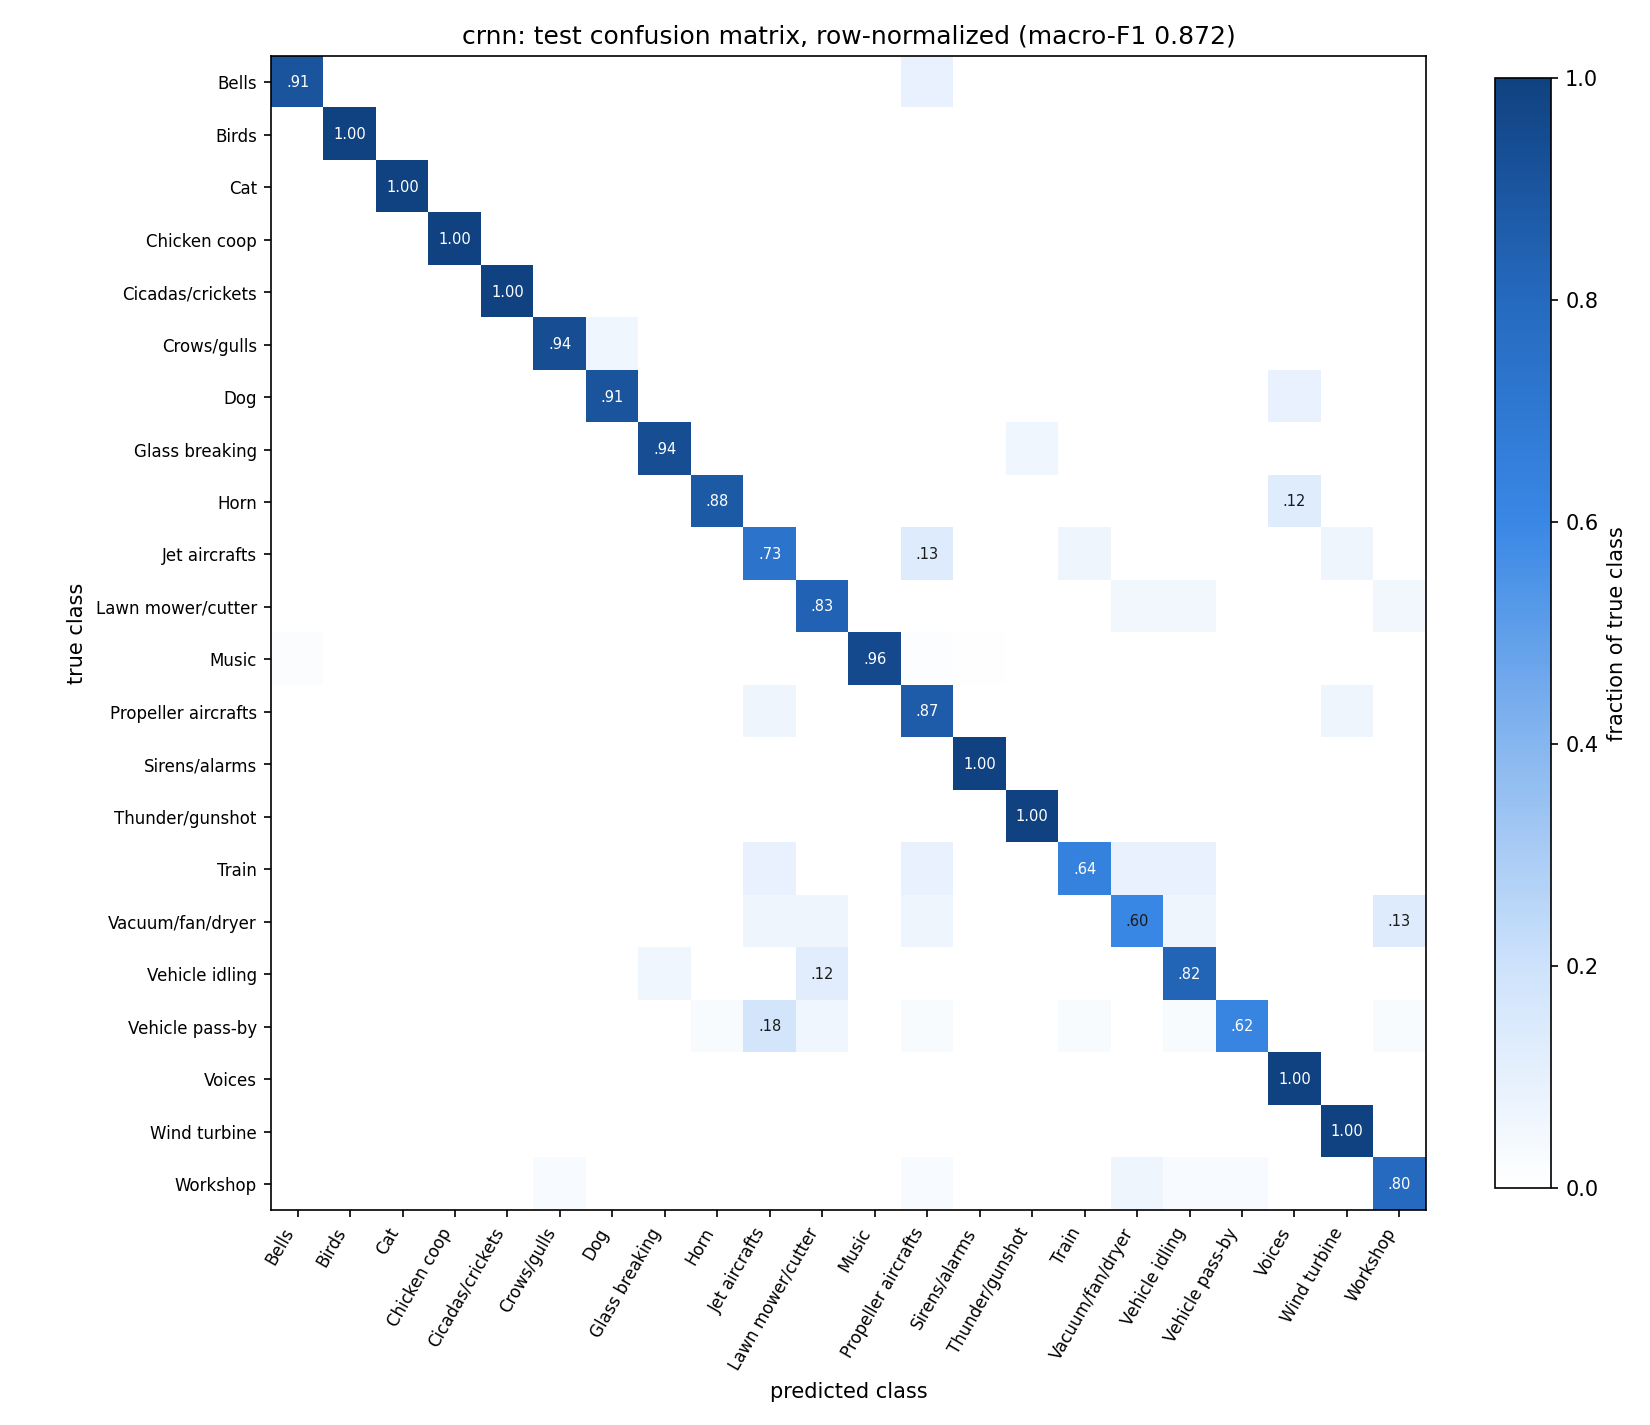

In [13]:
from src.utils import RESULTS

display(Image(filename=str(RESULTS / "figures" / "test_per_class_f1.png")))
display(Image(filename=str(RESULTS / "figures" / "confusion_small_cnn.png")))
display(Image(filename=str(RESULTS / "figures" / "confusion_mobilenetv3s.png")))
display(Image(filename=str(RESULTS / "figures" / "confusion_crnn.png")))

## 3. Leakage sensitivity

Source: `scripts/leakage_sensitivity.py`

Re-score saved test predictions without the test clips that share audio with a train/val clip.

The fixed split groups exact duplicates only; scripts/eda_quality.py also finds clips that are a prefix of another
clip or start with the same seconds. This script measures how much those few test clips change the reported
metrics, without retraining. Reads results/tables/eda_overlap_pairs.csv and results/predictions/*_test_*.csv.
Writes results/tables/midterm_leakage_sensitivity.csv.

In [14]:
import sys
from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from src.utils import RESULTS, load_classes

In [15]:
def main_leakage_sensitivity() -> None:
    classes = load_classes()
    pairs = pd.read_csv(RESULTS / "tables" / "eda_overlap_pairs.csv")
    cross = pairs[pairs.crosses_split]
    leaked = set(cross.loc[cross.split_a == "test", "sample_a"]) | set(cross.loc[cross.split_b == "test", "sample_b"])
    print(f"test clips sharing audio with train/val: {sorted(leaked)}")

    rows = []
    for f in sorted((RESULTS / "predictions").glob("*_test_none_0.csv")):
        p = pd.read_csv(f)
        for subset, d in (("all test clips", p), ("without overlapping clips", p[~p.sample_id.isin(leaked)])):
            rows.append({"model": p.model.iat[0], "seed": p.seed.iat[0], "subset": subset, "n": len(d),
                         "test_acc": accuracy_score(d.true_class, d.pred_class),
                         "test_macro_f1": f1_score(d.true_class, d.pred_class, labels=classes, average="macro",
                                                   zero_division=0)})
    out = pd.DataFrame(rows)
    out.round(4).to_csv(RESULTS / "tables" / "midterm_leakage_sensitivity.csv", index=False)
    wide = out.pivot_table(index=["model", "seed"], columns="subset", values="test_macro_f1")
    wide["delta"] = wide["without overlapping clips"] - wide["all test clips"]
    print(out.round(4).to_string(index=False))
    print("\nmacro-F1 change when the overlapping clips are removed:\n" + wide.round(4).to_string())

In [16]:
# same as: python scripts/leakage_sensitivity.py
sys.argv = ["scripts/leakage_sensitivity.py"]
main_leakage_sensitivity()

test clips sharing audio with train/val: ['Crows-0017', 'Olive shaker-0015']
       model  seed                    subset   n  test_acc  test_macro_f1
        crnn    42            all test clips 758    0.9301         0.8720
        crnn    42 without overlapping clips 756    0.9299         0.8713
        crnn    43            all test clips 758    0.9274         0.8664
        crnn    43 without overlapping clips 756    0.9272         0.8654
        crnn    44            all test clips 758    0.9367         0.8868
        crnn    44 without overlapping clips 756    0.9365         0.8863
mobilenetv3s    42            all test clips 758    0.9301         0.8700
mobilenetv3s    42 without overlapping clips 756    0.9299         0.8695
mobilenetv3s    43            all test clips 758    0.9578         0.9204
mobilenetv3s    43 without overlapping clips 756    0.9590         0.9221
mobilenetv3s    44            all test clips 758    0.9578         0.9138
mobilenetv3s    44 without overlapp

## 4. Midterm questions E1-E4

Source: `scripts/midterm_questions.py`

Midterm questions E1-E4 from the saved clean test predictions (no model is re-run).

E1  which classes are recognised best / worst          -> midterm_e1_per_class.csv, midterm_e1_class_ranking.csv
E2  which classes are confused most                    -> midterm_e2_confusion_pairs.csv, midterm_e2_hard_clips.csv,
                                                          midterm_e2_eda_overlap.csv (needs eda_spectral_similarity.csv
                                                          from scripts/eda.py), midterm_e2_audio_audit.csv + figures
                                                          (need audio, see below)
E3  does the CRNN beat the plain CNN on clips of       -> midterm_e3_duration_class_counts.csv,
    different original duration                           midterm_e3_duration_metrics.csv,
                                                          midterm_e3_paired_outcomes.csv, midterm_e3_duration_comparison.png
E4  accuracy-cost trade-off                            -> midterm_e4_tradeoff.csv, midterm_e4_tradeoff.png

Prediction CSVs are checked against the JSON logs first, as in plot_metrics.py. The E2 audio audit reads the
waveform cache (data/cache_22k, the exact model input) or, if it is missing, the raw 44.1 kHz wav files; its figures
also need torchaudio. Steps whose inputs are missing are skipped and their existing outputs are left untouched.

In [17]:
import argparse
import json
import sys
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import f1_score, precision_recall_fscore_support
from src.utils import RESULTS, load_classes, load_config, resolve

In [18]:
MODELS = ["small_cnn", "mobilenetv3s", "crnn"]
COLORS = {"small_cnn": "#2a78d6", "mobilenetv3s": "#eb6834", "crnn": "#1baf7a"}
# original clip duration vs the 5 s model window: padded / up to 3x the window / longer
DURATION_BINS = [0, 5, 15, np.inf]
DURATION_LABELS = ["short (<=5 s)", "medium (5-15 s)", "long (>15 s)"]
# Clips chosen by hand for listening: misclassified by at least 2 of the 3 seed-42 models, one per true class.
# The full candidate list is midterm_e2_hard_clips.csv.
AUDIT_IDS = ["Crows-0022", "Jet aircrafts-0003", "Lawn mower-0007", "Music-0004", "Helicopters-0035", "Train-0005",
             "fan-0019", "motorbike idling-0013", "car pass-by-0011", "Glass breaking-0001"]
AUDIT_FIGURES = 3  # spectrogram figures for the first clips of AUDIT_IDS

In [19]:
def load_predictions(seed: int, classes: list[str]) -> tuple[dict, dict]:
    pred, logs = {}, {}
    for m in MODELS:
        p = pd.read_csv(RESULTS / "predictions" / f"{m}_seed{seed}_test_none_0.csv").set_index("sample_id")
        logs[m] = json.loads((RESULTS / "logs" / f"{m}_seed{seed}.json").read_text(encoding="utf-8"))
        f1 = f1_score(p.true_class, p.pred_class, labels=classes, average="macro", zero_division=0)
        assert abs(f1 - logs[m]["test"]["macro_f1"]) < 1e-9, f"{m}: CSV and log disagree"
        p["p_pred"] = [max(json.loads(s)) for s in p.probabilities]
        pred[m] = p
    ids = pred[MODELS[0]].index
    assert all(pred[m].index.sort_values().equals(ids.sort_values()) for m in MODELS), "models saw different clips"
    pred = {m: pred[m].loc[ids] for m in MODELS}
    return pred, logs

In [20]:
def e1_classes(pred: dict, classes: list[str], tab_dir: Path) -> None:
    rows = []
    for m in MODELS:
        p, r, f, n = precision_recall_fscore_support(pred[m].true_class, pred[m].pred_class, labels=classes,
                                                     zero_division=0)
        rows.append(pd.DataFrame({"model": m, "class_name": classes, "precision": p, "recall": r, "f1": f,
                                  "n_test": n}))
    per_class = pd.concat(rows, ignore_index=True)
    per_class.to_csv(tab_dir / "midterm_e1_per_class.csv", index=False)

    rank = per_class.pivot(index="class_name", columns="model", values="f1")[MODELS]
    rank["F1_mean_3_models"] = rank[MODELS].mean(axis=1)
    rank["recall_mean_3_models"] = per_class.groupby("class_name").recall.mean()  # recall = per-class accuracy
    rank["n_test"] = per_class.groupby("class_name").n_test.first()
    rank = rank.sort_values("F1_mean_3_models", ascending=False, kind="stable")
    rank.to_csv(tab_dir / "midterm_e1_class_ranking.csv")
    print("E1 best:\n" + rank.head(3).round(3).to_string() + "\nE1 worst:\n" + rank.tail(3).round(3).to_string())

In [21]:
def e2_confusions(pred: dict, classes: list[str], tab_dir: Path) -> pd.DataFrame:
    """Unordered class pairs with at least one error, counted in both directions."""
    rows = []
    for m in MODELS:
        p = pred[m]
        n = p.true_class.value_counts()
        cnt = pd.crosstab(p.true_class, p.pred_class).reindex(index=classes, columns=classes, fill_value=0)
        for i, a in enumerate(classes):
            for b in classes[i + 1:]:
                ab, ba = int(cnt.at[a, b]), int(cnt.at[b, a])
                if ab + ba == 0:
                    continue
                r_ab, r_ba = ab / n[a], ba / n[b]
                rows.append({"model": m, "A": a, "B": b, "A_to_B": ab, "B_to_A": ba, "n_A": n[a], "n_B": n[b],
                             "total_errors": ab + ba, "rate_A_to_B": r_ab, "rate_B_to_A": r_ba,
                             "pair_rate": (r_ab + r_ba) / 2,
                             "direction": "two-way" if ab and ba else "one-way"})
    pairs = pd.DataFrame(rows)
    pairs.to_csv(tab_dir / "midterm_e2_confusion_pairs.csv", index=False)
    top = (pairs.groupby(["A", "B"]).total_errors.sum().sort_values(ascending=False, kind="stable").head(8))
    print("E2 most confused pairs (errors summed over the 3 models):\n" + top.to_string())

    # clips that at least 2 of the 3 models get wrong: candidates for listening
    first = pred[MODELS[0]]
    hard = pd.DataFrame({"true_class": first.true_class, "duration_s": first.duration})
    for m in MODELS:
        hard[m], hard[f"{m}_p_pred"] = pred[m].pred_class, pred[m].p_pred
    hard["n_models_wrong"] = sum((pred[m].pred_class != first.true_class).astype(int) for m in MODELS)
    hard = hard[hard.n_models_wrong >= 2].sort_values(["n_models_wrong", "true_class"], ascending=[False, True],
                                                      kind="stable")
    hard.to_csv(tab_dir / "midterm_e2_hard_clips.csv")
    print(f"E2 clips wrong for >= 2 models: {len(hard)} ({(hard.n_models_wrong == 3).sum()} wrong for all 3)")
    return pairs

In [22]:
def e2_eda_overlap(pairs: pd.DataFrame, classes: list[str], tab_dir: Path) -> None:
    """Spectral similarity from the dataset analysis (A6) next to the error counts of each class pair."""
    sim_path = tab_dir / "eda_spectral_similarity.csv"
    if not sim_path.exists():
        print(f"SKIP midterm_e2_eda_overlap.csv: {sim_path.name} missing (run scripts/eda.py)")
        return
    sim = pd.read_csv(sim_path, index_col=0).reindex(index=classes, columns=classes)
    errors = pairs.pivot_table(index=["A", "B"], columns="model", values="total_errors", fill_value=0)
    rows = []
    for i, a in enumerate(classes):
        for b in classes[i + 1:]:
            row = {"A": a, "B": b, "cosine": sim.at[a, b]}
            for m in MODELS:
                row[f"{m}_errors"] = int(errors[m].get((a, b), 0)) if m in errors else 0
            rows.append(row)
    out = pd.DataFrame(rows).sort_values("cosine", ascending=False, kind="stable")
    out.to_csv(tab_dir / "midterm_e2_eda_overlap.csv", index=False)
    err = out[[f"{m}_errors" for m in MODELS]].sum(axis=1)
    print(f"E2 Spearman(cosine, errors summed over models) = {out.cosine.corr(err, method='spearman'):.3f} "
          f"over {len(out)} pairs")

In [23]:
def e2_audio_audit(pred: dict, cfg: dict, fig_dir: Path, tab_dir: Path) -> None:
    """What the model actually saw for the hand-picked clips: padding, crop position and kept energy."""
    sr, n_sec = cfg["audio"]["sample_rate"], cfg["audio"]["duration_s"]
    cache = resolve(cfg["dataset"]["cache_dir"])
    if cache.is_dir():
        source = "cache"
    else:
        index_csv = resolve(cfg["dataset"]["index_csv"])
        if not index_csv.exists():
            print("SKIP midterm_e2_audio_audit.csv: neither the waveform cache nor data/index.csv is available")
            return
        import soundfile as sf
        index = pd.read_csv(index_csv).set_index("sample_id")
        raw = resolve(cfg["dataset"]["raw_dir"]) / "DATASEC"
        source = "raw"
    from src.data import crop_or_pad

    def load(sid: str) -> tuple[np.ndarray, int]:
        if source == "cache":
            return np.load(cache / f"{sid}.npy").astype(np.float32) / 32767.0, sr
        w, s = sf.read(raw / index.at[sid, "path"], dtype="float32", always_2d=True)
        return w.mean(axis=1), s

    first = pred[MODELS[0]]
    rows, windows = [], {}
    for sid in AUDIT_IDS:
        wav, s = load(sid)
        n = int(round(s * n_sec))
        win = crop_or_pad(wav, n, cfg["audio"]["eval_crop"], pad_mode=cfg["audio"].get("pad_mode", "zero"))
        windows[sid] = (win, s)
        row = {"sample_id": sid, "true_class": first.at[sid, "true_class"], "duration_s": len(wav) / s}
        for m in MODELS:
            row[m], row[f"{m}_p_pred"] = pred[m].at[sid, "pred_class"], pred[m].at[sid, "p_pred"]
        row["n_models_wrong"] = sum(pred[m].at[sid, "pred_class"] != row["true_class"] for m in MODELS)
        row["crop_start_s"] = max(len(wav) - n, 0) // 2 / s
        row["pad_fraction"] = max(n - len(wav), 0) / n
        row["duration_fraction_seen"] = min(1.0, n / len(wav))
        row["energy_kept"] = float(np.sum(win.astype(np.float64) ** 2) / np.sum(wav.astype(np.float64) ** 2))
        row["observation"] = (f"zero padding is {100 * row['pad_fraction']:.1f}% of the input" if len(wav) < n else
                              f"centre {n_sec:g} s of {row['duration_s']:.2f} s, "
                              f"{100 * row['energy_kept']:.0f}% of the clip energy")
        rows.append(row)
    pd.DataFrame(rows).to_csv(tab_dir / "midterm_e2_audio_audit.csv", index=False)
    print(f"E2 audio audit ({source} audio): {len(rows)} clips -> midterm_e2_audio_audit.csv")

    try:
        import torch
        from src.features import build_logmel
    except ImportError as e:
        print(f"SKIP midterm_e2_audit_*.png: {e}")
        return
    logmel = build_logmel(cfg)
    for sid in AUDIT_IDS[:AUDIT_FIGURES]:
        win, s = windows[sid]
        if s != sr:
            print(f"SKIP midterm_e2_audit_{sid}.png: needs the {sr} Hz waveform cache")
            continue
        db = logmel.log_mel(torch.from_numpy(win)[None])[0].numpy()
        fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
        axes[0].plot(np.arange(len(win)) / s, win, lw=0.4)
        axes[0].set_xlabel("time in model input (s)"); axes[0].set_ylabel("amplitude")
        axes[0].set_title("Window seen by the model")
        im = axes[1].imshow(db, origin="lower", aspect="auto", cmap="magma", extent=[0, len(win) / s, 0, db.shape[0]])
        axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("Mel band"); axes[1].grid(False)
        axes[1].set_title("log-Mel before normalisation")
        fig.colorbar(im, ax=axes[1], label="dB")
        fig.suptitle(f"{sid} (true: {first.at[sid, 'true_class']})", fontsize=10)
        plt.tight_layout(); plt.savefig(fig_dir / f"midterm_e2_audit_{sid}.png", dpi=150); plt.close()

In [24]:
def e3_duration(pred: dict, classes: list[str], seed: int, fig_dir: Path, tab_dir: Path) -> None:
    """Metrics inside groups of original clip duration. Only classes present in a group enter its macro-F1."""
    first = pred[MODELS[0]]
    group = pd.cut(first.duration, DURATION_BINS, labels=DURATION_LABELS)
    counts = pd.crosstab(first.true_class, group).reindex(index=classes, columns=DURATION_LABELS, fill_value=0)
    counts.rename_axis(index="macro_class", columns=None).to_csv(tab_dir / "midterm_e3_duration_class_counts.csv")

    rows, paired = [], []
    for g in DURATION_LABELS:
        mask = (group == g).to_numpy()
        present = sorted(first.true_class[mask].unique())
        f1 = {}
        for m in MODELS:
            p = pred[m][mask]
            f1[m] = f1_score(p.true_class, p.pred_class, labels=present, average="macro", zero_division=0)
            rows.append({"group": g, "model": m, "n": int(mask.sum()), "n_classes": len(present),
                         "accuracy": float((p.pred_class == p.true_class).mean()), "F1_present": f1[m]})
        cnn = (pred["small_cnn"].pred_class == first.true_class)[mask]
        crnn = (pred["crnn"].pred_class == first.true_class)[mask]
        only_cnn, only_crnn = int((cnn & ~crnn).sum()), int((~cnn & crnn).sum())
        paired.append({"group": g, "n": int(mask.sum()), "both_correct": int((cnn & crnn).sum()),
                       "only_CNN_correct": only_cnn, "only_CRNN_correct": only_crnn,
                       "both_wrong": int((~cnn & ~crnn).sum()), "delta_F1_CRNN_minus_CNN": f1["crnn"] - f1["small_cnn"],
                       # exact McNemar test on the discordant clips (one seed, so it ignores training variance)
                       "mcnemar_exact_p": binomtest(only_cnn, only_cnn + only_crnn).pvalue if only_cnn + only_crnn else 1.0})
    metrics, paired = pd.DataFrame(rows), pd.DataFrame(paired)
    metrics.to_csv(tab_dir / "midterm_e3_duration_metrics.csv", index=False)
    paired.to_csv(tab_dir / "midterm_e3_paired_outcomes.csv", index=False)
    print("E3 CRNN vs small_cnn by duration group:\n" + paired.round(3).to_string(index=False))

    plt.style.use("seaborn-v0_8-whitegrid")
    fig, ax = plt.subplots(figsize=(10, 4.2))
    x, w = np.arange(len(DURATION_LABELS)), 0.26
    for k, m in enumerate(MODELS):
        v = metrics[metrics.model == m].set_index("group").F1_present.reindex(DURATION_LABELS)
        bars = ax.bar(x + (k - 1) * w, v, width=w * 0.95, color=COLORS[m], label=m)
        ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    n = metrics.drop_duplicates("group").set_index("group").reindex(DURATION_LABELS)
    ax.set_xticks(x, [f"{g}\nn={r.n}, {r.n_classes} classes" for g, r in n.iterrows()])
    ax.set_ylim(0, 1.15); ax.set_ylabel("macro-F1 over classes present")
    ax.set_title(f"Test macro-F1 by original clip duration, seed {seed}")
    ax.legend(loc="upper center", ncol=3, frameon=True)
    plt.tight_layout(); plt.savefig(fig_dir / "midterm_e3_duration_comparison.png", dpi=150); plt.close()

In [25]:
def pareto(cost: pd.Series, score: pd.Series) -> pd.Series:
    """True if no other model is at least as cheap and at least as accurate, and strictly better in one."""
    return pd.Series([not any((cost[o] <= cost[m]) and (score[o] >= score[m]) and
                              ((cost[o] < cost[m]) or (score[o] > score[m])) for o in cost.index if o != m)
                      for m in cost.index], index=cost.index)

In [26]:
def e4_tradeoff(logs: dict, fig_dir: Path, tab_dir: Path) -> None:
    t = pd.DataFrame([{"model": m, "val_F1": L["val"]["macro_f1"], "test_F1": L["test"]["macro_f1"],
                       "test_acc": L["test"]["accuracy"], "params_M": L["params"] / 1e6, "MACs_M": L["macs"] / 1e6,
                       "latency_ms": L["latency_ms"], "train_min": L["train_time_s"] / 60,
                       "epochs_run": len(L["history"])} for m, L in logs.items()]).set_index("model")
    for c in ["latency_ms", "MACs_M", "params_M"]:
        t[f"pareto_{c}"] = pareto(t[c], t.test_F1)
    t.to_csv(tab_dir / "midterm_e4_tradeoff.csv")
    print("E4 trade-off:\n" + t.round(3).to_string())

    plt.style.use("seaborn-v0_8-whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    for ax, c, label in zip(axes, ["latency_ms", "MACs_M"], ["latency (ms / clip, T4, batch 1)", "MACs (M / clip)"]):
        for m in t.index:
            ax.scatter(t.at[m, c], t.at[m, "test_F1"], s=90, color=COLORS[m], zorder=3)
            ax.annotate(m, (t.at[m, c], t.at[m, "test_F1"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
        front = t[t[f"pareto_{c}"]].sort_values(c)
        ax.plot(front[c], front.test_F1, "--", color="gray", lw=1, label="Pareto front")
        ax.set_xlim(0, t[c].max() * 1.2); ax.set_ylim(t.test_F1.min() - 0.03, t.test_F1.max() + 0.03)
        ax.set_xlabel(label); ax.set_ylabel("test macro-F1"); ax.legend(loc="lower right", fontsize=8)
    fig.suptitle("Accuracy-cost trade-off (lower cost and higher F1 is better)", fontsize=11)
    plt.tight_layout(); plt.savefig(fig_dir / "midterm_e4_tradeoff.png", dpi=150); plt.close()

In [27]:
def main_midterm_questions() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()
    cfg, classes = load_config(), load_classes()
    fig_dir, tab_dir = RESULTS / "figures", RESULTS / "tables"
    fig_dir.mkdir(parents=True, exist_ok=True); tab_dir.mkdir(parents=True, exist_ok=True)

    pred, logs = load_predictions(args.seed, classes)
    e1_classes(pred, classes, tab_dir)
    pairs = e2_confusions(pred, classes, tab_dir)
    e2_eda_overlap(pairs, classes, tab_dir)
    e2_audio_audit(pred, cfg, fig_dir, tab_dir)
    e3_duration(pred, classes, args.seed, fig_dir, tab_dir)
    e4_tradeoff(logs, fig_dir, tab_dir)
    print(f"-> {tab_dir}/midterm_e*.csv, {fig_dir}/midterm_e*.png")

In [28]:
# same as: python scripts/midterm_questions.py --seed 42
sys.argv = ["scripts/midterm_questions.py", "--seed", "42"]
main_midterm_questions()

E1 best:
model                 small_cnn  mobilenetv3s   crnn  F1_mean_3_models  recall_mean_3_models  n_test
class_name                                                                                          
Voices                    0.997         0.993  0.995             0.995                 0.994     285
Cicadas and crickets      1.000         0.952  1.000             0.984                 0.970      11
Chicken coop              0.947         1.000  1.000             0.982                 1.000       9
E1 worst:
model           small_cnn  mobilenetv3s   crnn  F1_mean_3_models  recall_mean_3_models  n_test
class_name                                                                                    
Vehicle idling      0.737         0.647  0.778             0.721                 0.765      17
Jet aircrafts       0.759         0.690  0.629             0.692                 0.711      15
Train               0.640         0.560  0.700             0.633                 0.667      11
E

E2 audio audit (cache audio): 10 clips -> midterm_e2_audio_audit.csv


E3 CRNN vs small_cnn by duration group:
          group   n  both_correct  only_CNN_correct  only_CRNN_correct  both_wrong  delta_F1_CRNN_minus_CNN  mcnemar_exact_p
  short (<=5 s) 309           300                 3                  3           3                    0.020            1.000
medium (5-15 s) 140           117                 8                  5          10                   -0.006            0.581
   long (>15 s) 309           274                 6                  6          23                    0.030            1.000
E4 trade-off:
              val_F1  test_F1  test_acc  params_M   MACs_M  latency_ms  train_min  epochs_run  pareto_latency_ms  pareto_MACs_M  pareto_params_M
model                                                                                                                                           
small_cnn      0.860    0.878     0.934     0.394  198.408       1.169      3.183          50               True           True             True
mobilenetv3

-> C:\ATI\DataSEC-Sound-Classification-main\results\tables/midterm_e*.csv, C:\ATI\DataSEC-Sound-Classification-main\results\figures/midterm_e*.png


,class_name,small_cnn,mobilenetv3s,crnn,F1_mean_3_models,recall_mean_3_models,n_test
0,Voices,0.996503,0.992933,0.994746,0.994727,0.994152,285
1,Cicadas and crickets,1.000000,0.952381,1.000000,0.984127,0.969697,11
2,Chicken coop,0.947368,1.000000,1.000000,0.982456,1.000000,9
3,Music,0.986577,0.969492,0.976271,0.977447,0.964444,150
4,Thunder fireworks and gunshot,0.972222,0.956522,0.985915,0.971553,0.980952,35
5,Wind turbine,1.000000,0.967742,0.937500,0.968414,1.000000,15
6,Cat fights and moans,0.941176,0.933333,1.000000,0.958170,0.958333,8
7,Sirens and alarms,0.944444,0.944444,0.971429,0.953439,1.000000,17
8,Glass breaking,0.941176,0.969697,0.941176,0.950683,0.941176,17
9,Birds,1.000000,0.842105,1.000000,0.947368,0.962963,9


,group,n,both_correct,only_CNN_correct,only_CRNN_correct,both_wrong,delta_F1_CRNN_minus_CNN,mcnemar_exact_p
0,short (<=5 s),309,300,3,3,3,0.020360,1.000000
1,medium (5-15 s),140,117,8,5,10,-0.005920,0.581055
2,long (>15 s),309,274,6,6,23,0.029873,1.000000


,model,val_F1,test_F1,test_acc,params_M,MACs_M,latency_ms,train_min,epochs_run,pareto_latency_ms,pareto_MACs_M,pareto_params_M
0,small_cnn,0.860462,0.878348,0.934037,0.393974,198.407680,1.16910,3.182903,50,True,True,True
1,mobilenetv3s,0.871905,0.870021,0.930079,1.540406,18.114744,6.02475,2.452604,25,False,True,False
2,crnn,0.868783,0.872028,0.930079,0.868822,486.568960,1.46670,2.787911,42,False,False,False


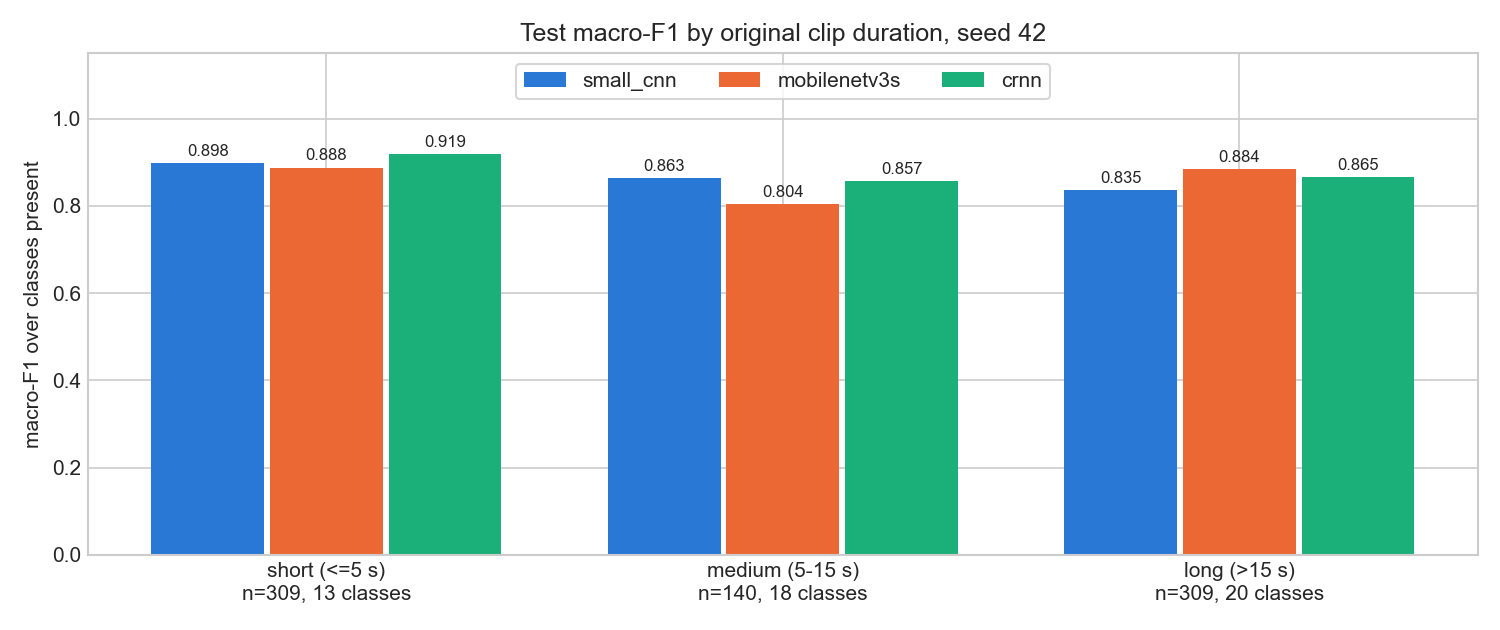

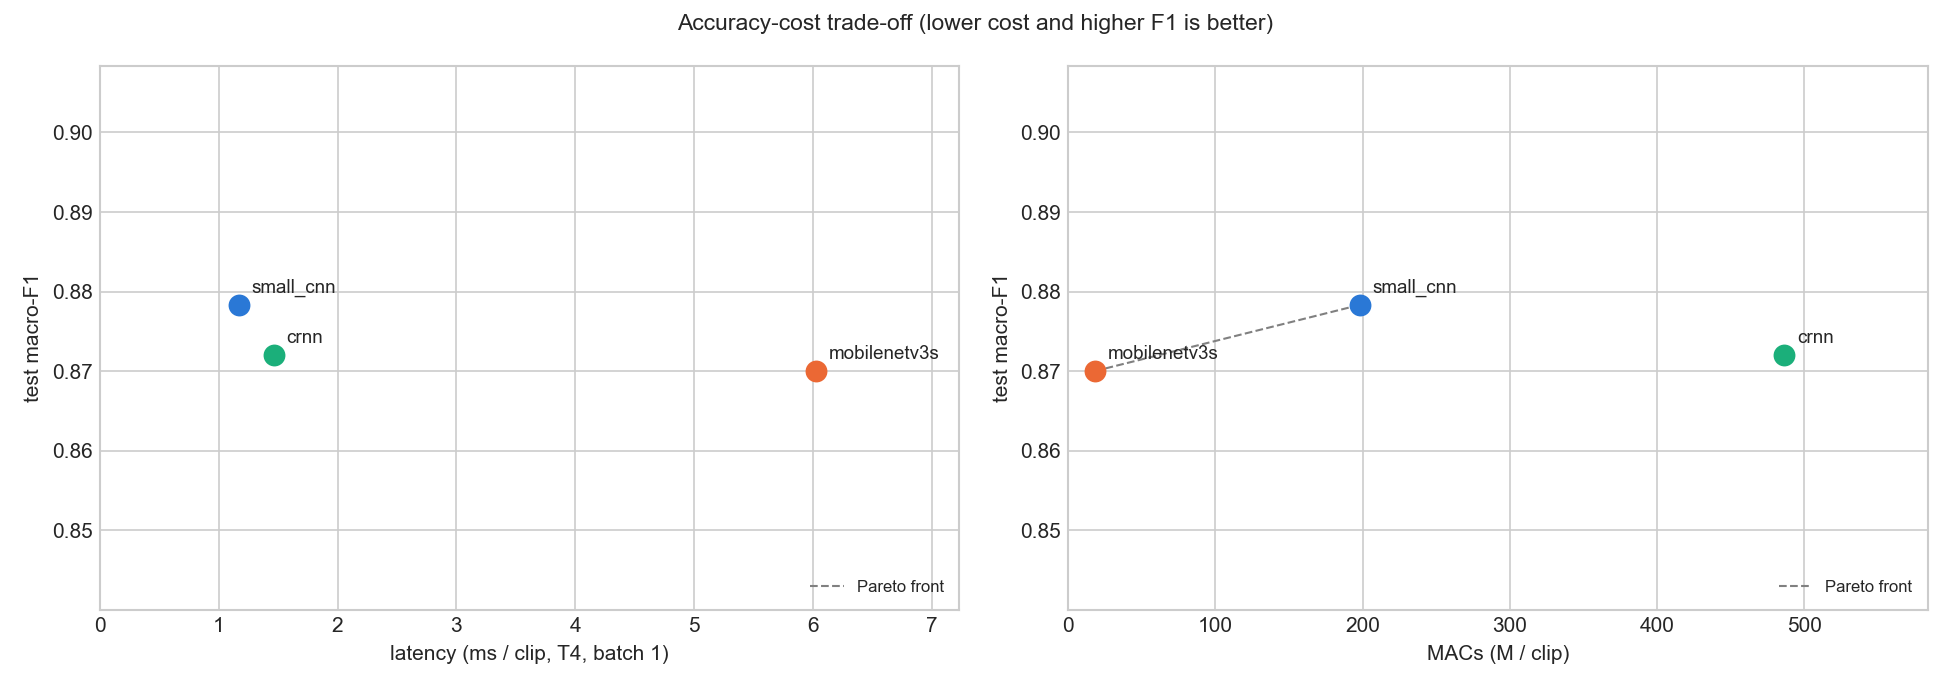

In [29]:
from src.utils import RESULTS

display(pd.read_csv(RESULTS / "tables" / "midterm_e1_class_ranking.csv"))
display(pd.read_csv(RESULTS / "tables" / "midterm_e3_paired_outcomes.csv"))
display(pd.read_csv(RESULTS / "tables" / "midterm_e4_tradeoff.csv"))
display(Image(filename=str(RESULTS / "figures" / "midterm_e3_duration_comparison.png")))
display(Image(filename=str(RESULTS / "figures" / "midterm_e4_tradeoff.png")))